In [ ]:
import pandas as pd

SOURCE_URL = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(SOURCE_URL)
original = df.copy(deep=True)
df.rename(columns={"sex": "gender"}, inplace=True)
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,gender,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


#### Missing entries per column

In [ ]:
print(f"Missing entries per column: {df.isna().sum()}")

Missing entries per column: species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
gender               11
year                  0
dtype: int64


Index the rows where `body_mass_g` is missing

In [ ]:
df.loc[df['body_mass_g'].isna()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,gender,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


Missing count for `gender` column

In [ ]:
missing_count = df['gender'].isna().sum()
missing_percent = 100 * missing_count / len(df)

print(f"Missing gender entries: {missing_count}")
print(f"Percent of rows: {missing_percent:.3f}%")

Missing gender entries: 11
Percent of rows: 3.198%


# Deletion: decide which fields matter

In [ ]:
complete_rows = df.dropna()
mass_rows = df.dropna(subset=["body_mass_g"])

print("Original rows:", len(df))
print("Rows with every field present:", len(complete_rows))
print("Rows with mass present:", len(mass_rows))

Original rows: 344
Rows with every field present: 333
Rows with mass present: 342


In [ ]:
df.shape

(344, 8)

# Fill a numeric column

When handling missing values in a dataset, choosing between mean and median imputation mainly depends on the distribution of your data and the presence of outliers.

Skewness and Suggested approach  
- [-0.5, +0.5] -> Mean  
- [-1, -0.5], or [+0.5, +1] ->	Investigate both  
- Below -1 or above +1	-> Median

These are guidelines, not strict statistical rules.

In [ ]:
df["body_mass_g"].skew()

np.float64(0.4703293304801231)

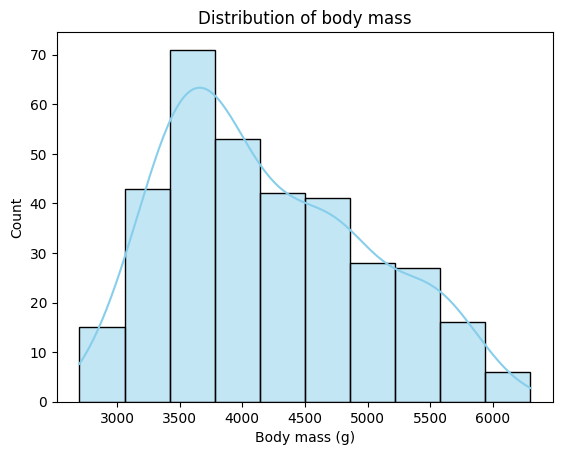

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["body_mass_g"], bins=10, kde=True, color='skyblue')
plt.xlabel('Body mass (g)')
plt.ylabel('Count')
plt.title('Distribution of body mass')
plt.show()

In [ ]:
mass_mean = df['body_mass_g'].mean()
mass_median = df['body_mass_g'].median()

mass_mean_filled = df['body_mass_g'].fillna(mass_mean)
mass_median_filled = df['body_mass_g'].fillna(mass_median)

print(f"Mean (g): {mass_mean:.2f}")
print("Median (g):", mass_median)
print(f"Missing after mean fill: {mass_mean_filled.isna().sum()}")
print(f"Missing after median fill: {mass_median_filled.isna().sum()}")

Mean (g): 4201.75
Median (g): 4050.0
Missing after mean fill: 0
Missing after median fill: 0


In [ ]:
mass_with_flag = pd.DataFrame({
    "mass_was_missing": df["body_mass_g"].isna(),
    "filled_mass_g": mass_median_filled
})
print(mass_with_flag.head())
print("\nRows whose mass was estimated:")
print(mass_with_flag.loc[mass_with_flag["mass_was_missing"]])

   mass_was_missing  filled_mass_g
0             False         3750.0
1             False         3800.0
2             False         3250.0
3              True         4050.0
4             False         3450.0

Rows whose mass was estimated:
     mass_was_missing  filled_mass_g
3                True         4050.0
271              True         4050.0


# ⭐️ Fill `body_mass_g` by species cluster

In [ ]:
df.loc[df['body_mass_g'].isna()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,gender,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


How it works:
- `groupby('species')` → Groups penguins by species.
- `transform('mean')` → Calculates each species' mean body mass and aligns it with each row.
- `fillna()` → Replaces missing values with their species' mean.

In [ ]:
species_mass_mean = df['body_mass_g'].fillna(df.groupby('species')['body_mass_g'].transform('mean'))
species_mass_mean

,body_mass_g
0,3750.000000
1,3800.000000
2,3250.000000
3,3700.662252
4,3450.000000
...,...
339,4000.000000
340,3400.000000
341,3775.000000
342,4100.000000


Beginner friendly commands

In [ ]:
df_copy = df.copy()

df_copy.loc[3, 'body_mass_g'] = df[df['species'] == 'Adelie']['body_mass_g'].mean()
df_copy.loc[271, 'body_mass_g'] = df[df['species'] == 'Gentoo']['body_mass_g'].mean()

In [ ]:
df_copy["body_mass_g"].isna().sum()

np.int64(0)

In [ ]:
mass_mean = df_copy['body_mass_g'].mean()
mass_median = df_copy['body_mass_g'].median()

print(f"Mean of Body mass when imputed by species mean: {mass_mean:.2f}g")
print(f"Median of Body mass when imputed by species median: {mass_median}g")

Mean of Body mass when imputed by species mean: 4202.84g
Median of Body mass when imputed by species median: 4050.0g


### `transform` examples

`transform()` applies a function and returns a result for every original row.

**-> Ex.1 Mean body mass by species**

Returns the mean body mass of each penguin's species for every row.

In [ ]:
df.groupby('species')['body_mass_g'].transform('mean')

,body_mass_g
0,3700.662252
1,3700.662252
2,3700.662252
3,3700.662252
4,3700.662252
...,...
339,3733.088235
340,3733.088235
341,3733.088235
342,3733.088235


**-> Ex.2 Subtract species mean from each value**

Shows how much heavier or lighter each penguin is compared to its species' average.

In [ ]:
mass_difference = df['body_mass_g'] - df.groupby('species')['body_mass_g'].transform('mean')
mass_difference

,body_mass_g
0,49.337748
1,99.337748
2,-450.662252
3,NaN
4,-250.662252
...,...
339,266.911765
340,-333.088235
341,41.911765
342,366.911765


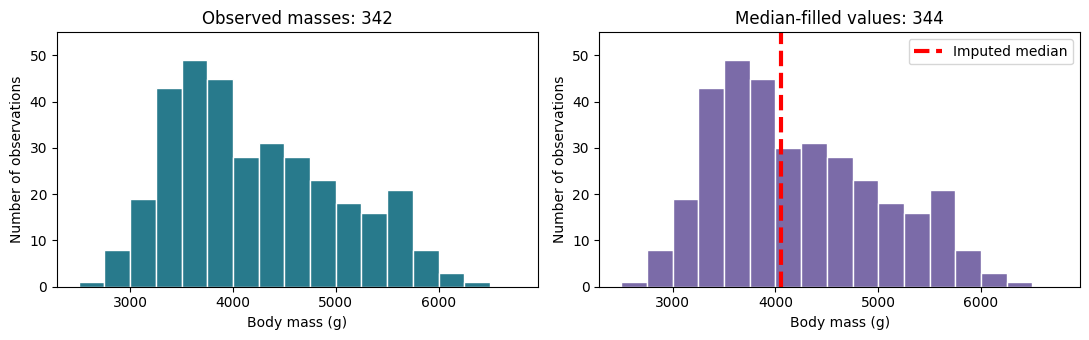

In [ ]:
import matplotlib.pyplot as plt


# Use identical bins and scales so the charts can be compared.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = list(range(2500, 6751, 250))
axes[0].hist(df["body_mass_g"].dropna(), bins=bins, color="#287A8C", edgecolor="white")
axes[1].hist(mass_median_filled, bins=bins, color="#7B6BA8", edgecolor="white")
axes[0].set_title("Observed masses: 342")
axes[1].set_title("Median-filled values: 344")


# Plot the original distribution
axes[1].hist(mass_median_filled, bins=bins, color="#7B6BA8", edgecolor="white")
# Highlight the median location
median = df["body_mass_g"].median()
axes[1].axvline(median, color="red", linewidth=3, linestyle="--", label="Imputed median")
axes[1].legend()


for ax in axes:
    ax.set_xlabel("Body mass (g)")
    ax.set_ylabel("Number of observations")
    ax.set_ylim(0, 55)
plt.tight_layout()
plt.show()


# Filling the text field `gender`

In [ ]:
gender_mode = df["gender"].mode().iloc[0]
gender_mode_filled = df["gender"].fillna(gender_mode)
gender_unknown_filled = df["gender"].fillna("Unknown")

print(f"Most frequent recorded category: {gender_mode}", end="\n\n")
print(f"Original counts, including missing: {df["gender"].value_counts(dropna=False)}", end="\n\n")
print(f"After mode filling: {gender_mode_filled.value_counts()}", end="\n\n")
print(f"After filling with Unknown: {gender_unknown_filled.value_counts()}")

Most frequent recorded category: male

Original counts, including missing: gender
male      168
female    165
NaN        11
Name: count, dtype: int64

After mode filling: gender
male      179
female    165
Name: count, dtype: int64

After filling with Unknown: gender
male       168
female     165
Unknown     11
Name: count, dtype: int64


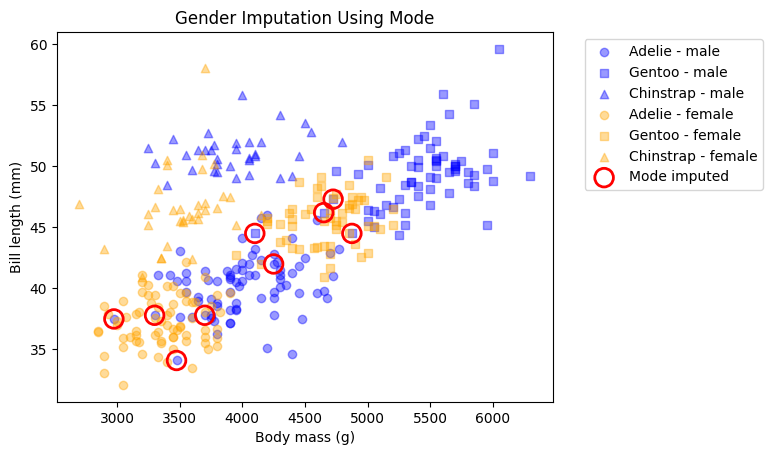

In [ ]:
import matplotlib.pyplot as plt

colors = {'male': 'blue', 'female': 'orange'}
markers = {'Adelie': 'o', 'Gentoo': 's', 'Chinstrap': '^'}

# Identify originally missing values
missing = df_copy['gender'].isna()

for sex in ['male', 'female']:
    for species in df_copy['species'].unique():
        subset = df_copy[(gender_mode_filled == sex) & (df_copy['species'] == species)]

        plt.scatter(subset['body_mass_g'], subset['bill_length_mm'],
                    color=colors[sex], marker=markers[species],
                    alpha=0.4, label=f'{species} - {sex}')

# Highlight mode-imputed values
plt.scatter(df_copy.loc[missing, 'body_mass_g'],
            df_copy.loc[missing, 'bill_length_mm'],
            facecolors='none', edgecolors='red',
            s=180, linewidths=2, label='Mode imputed')

plt.xlabel('Body mass (g)')
plt.ylabel('Bill length (mm)')
plt.title('Gender Imputation Using Mode')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

known = df['gender'].notna()
missing = df['gender'].isna()

# Train KNN on penguins with known sex
knn = make_pipeline(SimpleImputer(), StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(df.loc[known, features], df.loc[known, 'gender'])

# Fill missing sex
df.loc[missing, 'gender'] = knn.predict(df.loc[missing, features])

# See which rows were filled
print(df.loc[missing, ['species', 'gender']])

    species  gender
3    Adelie    male
8    Adelie  female
9    Adelie    male
10   Adelie  female
11   Adelie  female
47   Adelie  female
178  Gentoo  female
218  Gentoo  female
256  Gentoo  female
268  Gentoo    male
271  Gentoo    male


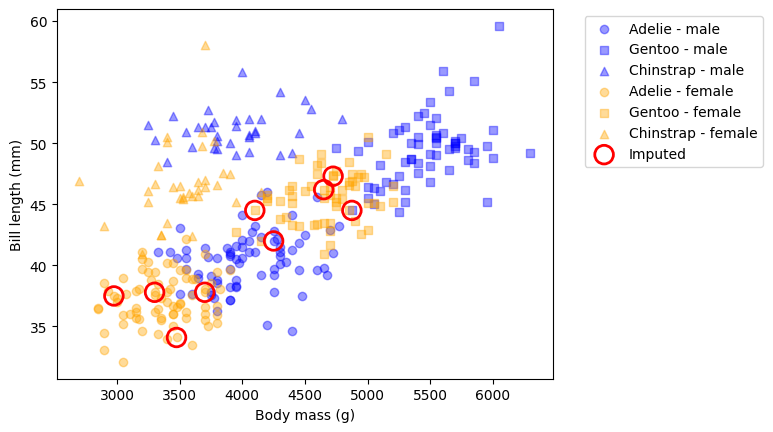

In [ ]:
colors = {'male': 'blue', 'female': 'orange'}
markers = {'Adelie': 'o', 'Gentoo': 's', 'Chinstrap': '^'}

for sex in ['male', 'female']:
    for species in df['species'].unique():
        subset = df[(df['gender'] == sex) & (df['species'] == species)]

        plt.scatter(subset['body_mass_g'], subset['bill_length_mm'],
                    c=colors[sex], marker=markers[species],
                    alpha=0.4, label=f'{species} - {sex}')

# Highlight imputed penguins
plt.scatter(df.loc[missing, 'body_mass_g'],
            df.loc[missing, 'bill_length_mm'],
            facecolors='none', edgecolors='red',
            s=180, linewidths=2, label='Imputed')

plt.xlabel('Body mass (g)')
plt.ylabel('Bill length (mm)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# Dates demo

In [ ]:
date_demo = df.head(6).copy()
date_demo["demo_batch_date"] = pd.to_datetime([None, "2026-11-04", None, "2026-11-06", None, None])
print(date_demo[["species", "demo_batch_date"]])
print("Missing demo dates:", date_demo["demo_batch_date"].isna().sum())

  species demo_batch_date
0  Adelie             NaT
1  Adelie      2026-11-04
2  Adelie             NaT
3  Adelie      2026-11-06
4  Adelie             NaT
5  Adelie             NaT
Missing demo dates: 4


Approach #1: constant fill

In [ ]:
# The documented date belongs to this demonstration batch only.
known_demo_batch_date = pd.Timestamp("2026-11-04")
date_demo["constant_fill"] = date_demo["demo_batch_date"].fillna(known_demo_batch_date)
print(date_demo[["demo_batch_date", "constant_fill"]])

  demo_batch_date constant_fill
0             NaT    2026-11-04
1      2026-11-04    2026-11-04
2             NaT    2026-11-04
3      2026-11-06    2026-11-06
4             NaT    2026-11-04
5             NaT    2026-11-04


Approach #2: forward and backward fill

In [ ]:
date_demo["forward_fill"] = date_demo["demo_batch_date"].ffill()
date_demo["backward_fill"] = date_demo["demo_batch_date"].bfill()

print(date_demo[["demo_batch_date", "forward_fill", "backward_fill"]])
print("Forward-fill gaps left:", date_demo["forward_fill"].isna().sum())
print("Backward-fill gaps left:", date_demo["backward_fill"].isna().sum())

  demo_batch_date forward_fill backward_fill
0             NaT          NaT    2026-11-04
1      2026-11-04   2026-11-04    2026-11-04
2             NaT   2026-11-04    2026-11-06
3      2026-11-06   2026-11-06    2026-11-06
4             NaT   2026-11-06           NaT
5             NaT   2026-11-06           NaT
Forward-fill gaps left: 1
Backward-fill gaps left: 2
